In [12]:
# TF-IDF + Linear SVM for binary jailbreak detection on dataset v2.
# Labels: 1 = adversarial / jailbreak, 0 = benign / non-jailbreak (not necessarily harmless).
import sys, json
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import ConfusionMatrixDisplay

# Find the repository root (works from any folder) and import the shared project code.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/task_a").is_dir())
sys.path.insert(0, str(ROOT / "src"))
from task_a.binary_metrics import headline_metrics
from task_a.leakage import comparison_key
from task_a.tfidf_baseline import load_rows, group_by_split, evaluate, write_run

In [13]:
# Load this model's settings plus the baseline settings it shares (dataset path, seed, TF-IDF settings), then dataset v2.
config = json.loads((ROOT / "configs/task_a_binary_tfidf_linear_svm_v2.json").read_text(encoding="utf-8"))
base = json.loads((ROOT / config["base_config"]).read_text(encoding="utf-8"))
SEED = base["seed"]
np.random.seed(SEED)
rows, dataset_sha256 = load_rows(ROOT / base["dataset"],
                                 columns=["example_id", "text", "label", "source_dataset", "split", "family_id", "source_binary_label"])
df = pd.DataFrame(rows)
data = group_by_split(rows)  # {"train": [...], "validation": [...], "test_official": [...], "test_jailbreakhub": [...]}

In [14]:
# Sanity checks: expected splits and labels, near-duplicate "families" kept inside one split,
# no test prompt also in train/validation (case and spacing ignored), and the official test unchanged.
assert set(df["split"]) == {"train", "validation", "test_official", "test_jailbreakhub"}
assert set(df["label"]) == {0, 1}
assert df.groupby("family_id")["split"].nunique().max() == 1, "a near-duplicate family appears in two splits"

training_keys = set(df.loc[df["split"].isin(["train", "validation"]), "text"].map(comparison_key))
test_keys = df.loc[df["split"].isin(["test_official", "test_jailbreakhub"]), "text"].map(comparison_key)
assert not test_keys.isin(training_keys).any(), "a test prompt also appears in train/validation"

raw_test = pd.read_parquet(ROOT / "data/raw/wildguard_test.parquet", columns=["prompt", "adversarial"])
official = df[df["split"] == "test_official"]
assert sorted(zip(official["text"], official["label"])) == sorted(zip(raw_test["prompt"], raw_test["adversarial"].astype(int))), \
    "official test differs from data/raw/wildguard_test.parquet"
print(f"All checks passed for {len(df):,} prompts.")

All checks passed for 63,841 prompts.


In [15]:
# Dataset summary: benign and adversarial prompts per split and source.
summary = pd.crosstab([df["split"], df["source_dataset"]], df["label"]).rename(columns={0: "Benign", 1: "Adversarial"})
summary["Total"] = summary["Benign"] + summary["Adversarial"]
summary.reindex(["train", "validation", "test_official", "test_jailbreakhub"], level=0)

label                             Benign  Adversarial  Total
split             source_dataset                            
train             jailbreakhub     10271         1183  11454
                  wildguardmix     22397        20606  43003
validation        jailbreakhub      1298          142   1440
                  wildguardmix      2482         2290   4772
test_official     wildguardmix       915          810   1725
test_jailbreakhub jailbreakhub      1301          141   1442
                  wildguardmix         5            0      5

In [16]:
# TF-IDF features (word 1-2 grams, min_df, sublinear TF), learned from the training prompts only.
tfidf = base["model"]
vectorizer = TfidfVectorizer(ngram_range=tuple(tfidf["ngram_range"]), min_df=tfidf["min_df"], sublinear_tf=True, lowercase=True)
X_train = vectorizer.fit_transform([r["text"] for r in data["train"]])
y_train = [r["label"] for r in data["train"]]
X_validation = vectorizer.transform([r["text"] for r in data["validation"]])
print(f"TF-IDF vocabulary: {len(vectorizer.vocabulary_):,} terms from {X_train.shape[0]:,} training prompts")

TF-IDF vocabulary: 462,820 terms from 54,457 training prompts


In [17]:
# Train one Linear SVM per C (smaller C = simpler model); keep the best validation macro-F1, ties to the smaller C.
# LinearSVC gives decision scores (signed distance to the boundary), not probabilities; >= 0 means adversarial.
assert config["c_grid"] == sorted(config["c_grid"])
c_search, best_c, best_f1, best_classifier = [], None, -1.0, None
for c in config["c_grid"]:
    classifier = LinearSVC(C=c, class_weight=tfidf["class_weight"], max_iter=config["max_iter"], random_state=SEED).fit(X_train, y_train)
    val_metrics, _ = evaluate(data["validation"], classifier.decision_function(X_validation), config["threshold"])
    val_f1 = val_metrics["all"]["macro_f1"]
    train_f1 = evaluate(data["train"], classifier.decision_function(X_train), config["threshold"])[0]["all"]["macro_f1"]  # shown only, not used to choose
    c_search.append({"C": c, "train_macro_f1": train_f1, "validation_macro_f1": val_f1})
    print(f"C = {c:<5}  train macro-F1 = {train_f1:.3f}  validation macro-F1 = {val_f1:.3f}")
    if val_f1 > best_f1:
        best_c, best_f1, best_classifier = c, val_f1, classifier

model = make_pipeline(vectorizer, best_classifier)  # raw text in, score out
print(f"\nSelected C = {best_c} (validation macro-F1 = {best_f1:.3f})")

C = 0.01   train macro-F1 = 0.966  validation macro-F1 = 0.960
C = 0.1    train macro-F1 = 0.986  validation macro-F1 = 0.975
C = 1.0    train macro-F1 = 0.999  validation macro-F1 = 0.981
C = 10.0   train macro-F1 = 1.000  validation macro-F1 = 0.981

Selected C = 1.0 (validation macro-F1 = 0.981)


In [18]:
# With C fixed, score validation and then each test set exactly once.
split_names = {"validation": "Validation", "test_official": "Official WildGuardMix test", "test_jailbreakhub": "JailbreakHub test"}
results, predictions = {}, []
for split in split_names:
    scores = model.decision_function([r["text"] for r in data[split]])
    results[split], preds = evaluate(data[split], scores, config["threshold"])
    predictions += [{"example_id": r["example_id"], "split": split, "gold": r["label"], "score": round(float(s), 6), "pred": p}
                    for r, s, p in zip(data[split], scores, preds)]

In [19]:
# Results: "adversarial" scores treat jailbreaks as the positive class; false-positive rate = benign prompts flagged.
table = pd.DataFrame({name: headline_metrics(results[split]["all"]) for split, name in split_names.items()})
table.style.format("{:.3f}", na_rep="n/a")

,Validation,Official WildGuardMix test,JailbreakHub test
Accuracy,0.982,0.995,0.935
Macro-F1,0.981,0.995,0.820
Adversarial precision,0.980,0.993,0.658
Adversarial recall,0.974,0.998,0.695
Adversarial F1,0.977,0.995,0.676
False-positive rate,0.013,0.007,0.039


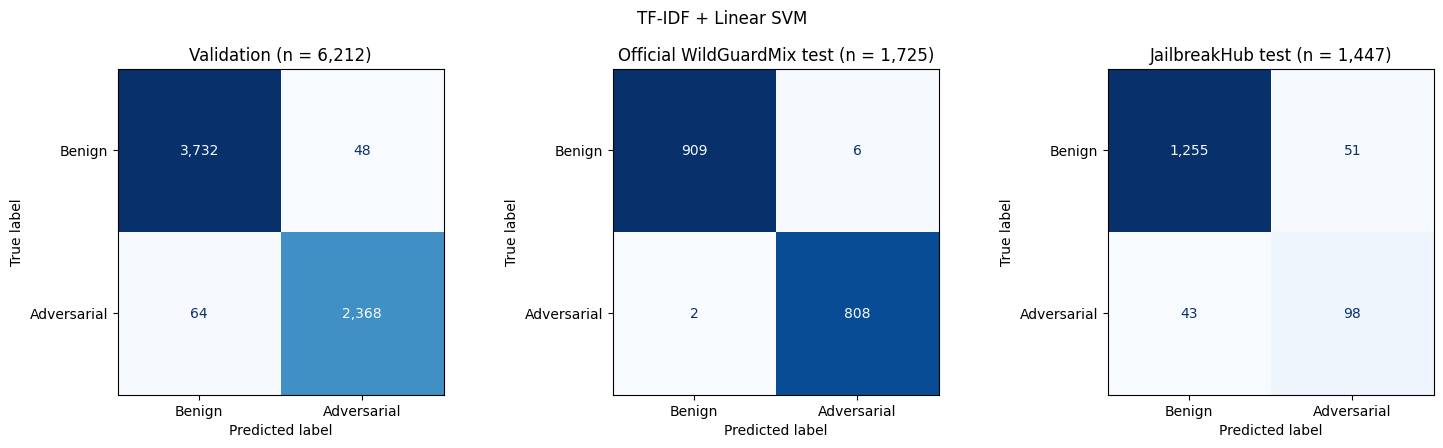

In [20]:
# Confusion matrices: rows are the true labels, columns are the model's predictions.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (split, name) in zip(axes, split_names.items()):
    cm = results[split]["all"]["confusion_matrix"]
    counts = np.array([[cm["tn"], cm["fp"]], [cm["fn"], cm["tp"]]])
    ConfusionMatrixDisplay(counts, display_labels=["Benign", "Adversarial"]).plot(ax=ax, cmap="Blues", values_format=",d", colorbar=False)
    ax.set_title(f"{name} (n = {counts.sum():,})")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
fig.suptitle("TF-IDF + Linear SVM")
fig.tight_layout()

In [21]:
# Overfitting check: the same model scored on its own training data vs unseen validation data, per source.
# A large positive gap means the model fits training prompts much better than new ones.
train_results, _ = evaluate(data["train"], best_classifier.decision_function(X_train), config["threshold"])
overfit = pd.DataFrame({name: {"Train macro-F1": train_results[source]["macro_f1"],
                                "Validation macro-F1": results["validation"][source]["macro_f1"]}
                        for source, name in [("all", "All"), ("wildguardmix", "WildGuardMix"), ("jailbreakhub", "JailbreakHub")]}).T
overfit["Gap (train - validation)"] = overfit["Train macro-F1"] - overfit["Validation macro-F1"]
overfit.style.format("{:.3f}", na_rep="n/a")

,Train macro-F1,Validation macro-F1,Gap (train - validation)
All,0.999,0.981,0.018
WildGuardMix,1.000,0.994,0.006
JailbreakHub,0.987,0.831,0.157


In [22]:
# Save settings, metrics, predictions, the model and the figure to a new timestamped folder.
changed_labels = int((df["label"] != df["source_binary_label"]).sum())
run_dir = ROOT / config["output_dir"] / datetime.now(timezone.utc).strftime("run_%Y%m%dT%H%M%SZ")
record = {"created_utc": datetime.now(timezone.utc).isoformat(), "interface": "notebooks/task_a_binary_tfidf_linear_svm_v2.ipynb",
          "config": config, "base_config": base, "seed": SEED, "dataset_sha256": dataset_sha256,
          "score_type": "LinearSVC decision score (not a probability)", "selected_C": best_c, "selected_validation_macro_f1": best_f1, "c_search": c_search, "train_metrics": train_results,
          "label_provenance": f"WildGuardMix adversarial flag; JailbreakHub labels with {changed_labels} reviewed "
                              "(not human-verified) corrections and 13 ambiguous rows excluded; other JailbreakHub labels unreviewed.",
          "versions": {"python": sys.version.split()[0], "scikit_learn": sklearn.__version__}}
write_run(run_dir, record, results, predictions, model=model)
fig.savefig(run_dir / "confusion_matrices.png", dpi=150, bbox_inches="tight")
print("Results saved to", run_dir.relative_to(ROOT))

Results saved to results\task_a_binary_tfidf_linear_svm_v2\run_20261021T022904Z


In [23]:
# Conclusion generated from the results table above ("nan" would mean a score is undefined).
official, jailbreakhub = table["Official WildGuardMix test"], table["JailbreakHub test"]
print(f"Selected C = {best_c} by validation macro-F1 ({best_f1:.3f}).")
print(f"Macro-F1: {official['Macro-F1']:.3f} on the official WildGuardMix test, {jailbreakhub['Macro-F1']:.3f} on the JailbreakHub test "
      f"(gap {official['Macro-F1'] - jailbreakhub['Macro-F1']:+.3f}; positive means the official test scored higher).")
print(f"Adversarial recall: {official['Adversarial recall']:.3f} official, {jailbreakhub['Adversarial recall']:.3f} JailbreakHub. "
      f"False-positive rate: {official['False-positive rate']:.3f} official, {jailbreakhub['False-positive rate']:.3f} JailbreakHub.")
print(f"Overfitting check (train minus validation macro-F1): {overfit.loc['All', 'Gap (train - validation)']:+.3f} overall, "
      f"{overfit.loc['WildGuardMix', 'Gap (train - validation)']:+.3f} WildGuardMix, {overfit.loc['JailbreakHub', 'Gap (train - validation)']:+.3f} JailbreakHub.")
print(f"Main limitation: labels are source-defined; {changed_labels} JailbreakHub labels come from reviewed corrections "
      "that are not human-verified, and the other JailbreakHub labels are unreviewed and may be noisy.")

Selected C = 1.0 by validation macro-F1 (0.981).
Macro-F1: 0.995 on the official WildGuardMix test, 0.820 on the JailbreakHub test (gap +0.175; positive means the official test scored higher).
Adversarial recall: 0.998 official, 0.695 JailbreakHub. False-positive rate: 0.007 official, 0.039 JailbreakHub.
Overfitting check (train minus validation macro-F1): +0.018 overall, +0.006 WildGuardMix, +0.157 JailbreakHub.
Main limitation: labels are source-defined; 174 JailbreakHub labels come from reviewed corrections that are not human-verified, and the other JailbreakHub labels are unreviewed and may be noisy.
